# Faster R-CNN — small dataset baseline (notebook 07)

Direct counterpart to notebook 03 (YOLOv8n small-dataset baseline): same dataset
split (`data/processed/RDD2022_4classes_small`, 277/60/60 images), same image
size (640), and the same *effective* batch size (8), so the two are as close to
apples-to-apples as the architectures allow.

Model: `fasterrcnn_resnet50_fpn_v2` (COCO-pretrained), internal resize capped to
640px (torchvision's default is ~800/1333px — capping it is the main change that
keeps this runnable on a local 8GB GPU). Training/eval logic lives in
`src/training/fasterrcnn.py` so it isn't duplicated between this notebook and the
later medium-dataset run.

Resource-saving choices (see `src/training/fasterrcnn.py` for details):
- batch_size=2, accum_steps=4 → effective batch 8, but only 2 samples in GPU memory at once
- automatic mixed precision (AMP)
- num_workers=0 → no background data-loading processes
- early stopping on val_loss (patience=10), same idea as YOLO's `patience`

A 1-epoch smoke test on this exact config measured **~155s/epoch and ~1.7GB peak
GPU memory** — safely inside an 8GB budget.

In [1]:
import sys
from pathlib import Path

import torch
import pandas as pd
import matplotlib.pyplot as plt

sys.path.append("..")
from src.training.fasterrcnn import (
    build_model, build_dataloaders, TrainConfig, get_device, fit, evaluate, CLASS_NAMES,
)

torch.manual_seed(42)

## Dataset

Same split used for the YOLOv8n small-dataset baseline (notebook 03).

In [2]:
DATASET_DIR = Path("../data/processed/RDD2022_4classes_small")
BATCH_SIZE = 2   # real per-step batch (kept small for GPU memory)
WORKERS = 0

train_loader, val_loader, test_loader = build_dataloaders(DATASET_DIR, batch_size=BATCH_SIZE, workers=WORKERS)

print(f"train: {len(train_loader.dataset)} images ({len(train_loader)} batches)")
print(f"val:   {len(val_loader.dataset)} images ({len(val_loader)} batches)")
print(f"test:  {len(test_loader.dataset)} images ({len(test_loader)} batches)")

train: 277 images (139 batches)
val:   60 images (30 batches)
test:  60 images (30 batches)


## Model

Faster R-CNN, ResNet50-FPN v2 backbone, COCO-pretrained, head replaced for 4 damage classes + background. Internal resize capped to imgsz=640 to match YOLO and reduce memory/compute.

In [3]:
DEVICE = get_device()
print("Device:", DEVICE)

IMGSZ = 640
model = build_model(imgsz=IMGSZ)
model.to(DEVICE)

total_params = sum(p.numel() for p in model.parameters())
print(f"Parameters: {total_params / 1e6:.1f}M")
print(f"Internal resize: {model.transform.min_size} / {model.transform.max_size}")

Device: cuda
Parameters: 43.3M
Internal resize: (640,) / 640


## Training configuration

Matched to YOLOv8n notebook 03 where the architectures allow:

| | YOLOv8n (nb03) | Faster R-CNN (this notebook) |
|---|---|---|
| epochs (max) | 30 | 30 |
| imgsz | 640 | 640 |
| effective batch | 8 | 8 (2 × 4 grad-accum steps) |
| early stopping | (default, effectively unlimited) | patience=30 (== epochs, i.e. runs the full budget) |

SGD with step decay, kept simple/explainable per project conventions.

In [4]:
cfg = TrainConfig(
    epochs=30,
    patience=30,        # == epochs: let it run the full budget, like YOLO nb03 did
    learning_rate=0.005,
    momentum=0.9,
    weight_decay=0.0005,
    step_size=10,
    gamma=0.1,
    accum_steps=4,      # 2 * 4 = effective batch 8
    amp=True,
)
print(cfg)

TrainConfig(epochs=30, patience=30, learning_rate=0.005, momentum=0.9, weight_decay=0.0005, step_size=10, gamma=0.1, accum_steps=4, amp=True, grad_clip=5.0)


## Training loop

Checkpoints (`last.pt`, `best.pt` by lowest val_loss) and `results.csv` are saved under `models/fasterrcnn_small/`.

In [5]:
RUN_DIR = Path("../models/fasterrcnn_small")

history_df = fit(model, train_loader, val_loader, DEVICE, RUN_DIR, cfg=cfg, progress=True)
print(f"Epochs run: {len(history_df)} (max was {cfg.epochs}, patience {cfg.patience})")
history_df

epochs:   0%|          | 0/30 [00:00<?, ?epoch/s]

Epochs run: 30 (max was 30, patience 30)


,epoch,train_loss,val_loss,time_s
0,1,1.038203,0.505301,34.789879
1,2,0.522941,0.517539,33.521968
2,3,0.513974,0.484203,34.115043
3,4,0.469170,0.483753,34.170684
4,5,0.422830,0.502293,33.759755
5,6,0.382748,0.500557,33.840124
6,7,0.347425,0.514957,34.598538
7,8,0.312526,0.543267,33.718707
8,9,0.284011,0.568439,33.931721
9,10,0.254528,0.571585,33.848162


## Loss curve

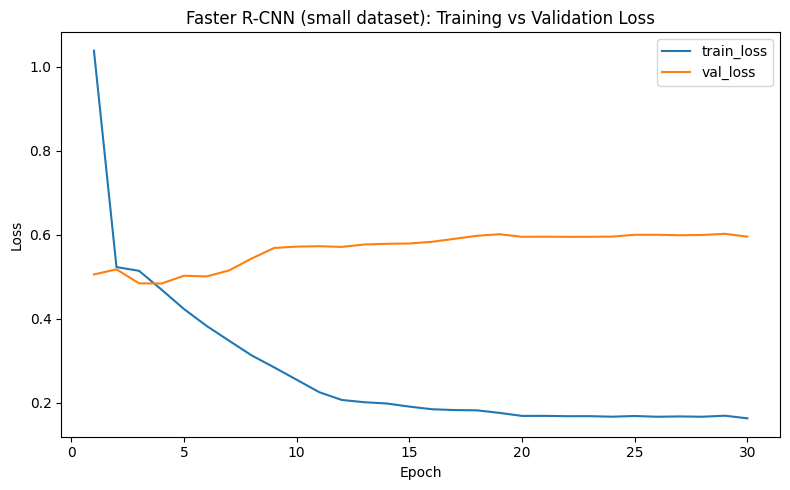

In [6]:
plt.figure(figsize=(8, 5))
plt.plot(history_df["epoch"], history_df["train_loss"], label="train_loss")
plt.plot(history_df["epoch"], history_df["val_loss"], label="val_loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Faster R-CNN (small dataset): Training vs Validation Loss")
plt.legend()
plt.tight_layout()
plt.savefig("fasterrcnn_small_loss_curve.png", bbox_inches="tight")
plt.show()

## Test-set evaluation

Loads `best.pt` and computes the same metric set YOLO's `val()` reports:
precision, recall, F1 (all at a fixed 0.5 confidence / 0.5 IoU threshold, via
greedy matching — see `evaluate()` in `src/training/fasterrcnn.py`), plus
mAP50 / mAP50-95 (via `torchmetrics`) and average inference time.

In [7]:
model.load_state_dict(torch.load(RUN_DIR / "best.pt", map_location=DEVICE))

# Sweeps confidence thresholds and reports P/R/F1 at the best-F1 operating
# point, the same idea as the single P/R number YOLO's val() reports.
results = evaluate(model, test_loader, DEVICE, iou_threshold=0.5)

print(f"Precision:           {results['precision']:.3f}  (at confidence >= {results['best_threshold']})")
print(f"Recall:              {results['recall']:.3f}")
print(f"F1:                  {results['f1']:.3f}")
print(f"mAP50:                {results['mAP50']:.4f}")
print(f"mAP50-95:             {results['mAP50-95']:.4f}")
print(f"Avg inference time:  {results['avg_inference_ms']:.1f} ms/image")

Precision:           0.227  (at confidence >= 0.4)
Recall:              0.205
F1:                  0.216
mAP50:                0.1356
mAP50-95:             0.0431
Avg inference time:  84.9 ms/image


In [8]:
raw = results["raw_torchmetrics"]
seen = raw["classes"].tolist()
rows = []
for cid, cname in CLASS_NAMES.items():
    if cid in seen:
        idx = seen.index(cid)
        rows.append({
            "class": cname,
            "mAP50-95": round(raw["map_per_class"][idx].item(), 4),
            "mean_recall@100": round(raw["mar_100_per_class"][idx].item(), 4),
        })

per_class_df = pd.DataFrame(rows)
per_class_df

,class,mAP50-95,mean_recall@100
0,D00_Longitudinal_Crack,0.0366,0.2755
1,D10_Transverse_Crack,0.0486,0.2314
2,D20_Alligator_Crack,0.0338,0.2444
3,D40_Pothole,0.0533,0.3742


## Comparison with the YOLOv8n small-dataset baseline (notebook 03)

Same dataset split, same imgsz, same effective batch size — the closest apples-to-apples comparison available given the architectural differences.

In [9]:
comparison_df = pd.DataFrame([
    {
        "model": "YOLOv8n (small dataset, nb03)",
        "precision": 0.368,
        "recall": 0.305,
        "f1": 0.334,
        "mAP50": 0.297,
        "mAP50-95": 0.119,
        "inference_ms": None,
    },
    {
        "model": "Faster R-CNN ResNet50-FPN v2 (small dataset, nb07)",
        "precision": round(results["precision"], 3),
        "recall": round(results["recall"], 3),
        "f1": round(results["f1"], 3),
        "mAP50": round(results["mAP50"], 4),
        "mAP50-95": round(results["mAP50-95"], 4),
        "inference_ms": round(results["avg_inference_ms"], 1),
    },
])

comparison_df

,model,precision,recall,f1,mAP50,mAP50-95,inference_ms
0,"YOLOv8n (small dataset, nb03)",0.368,0.305,0.334,0.2970,0.1190,NaN
1,"Faster R-CNN ResNet50-FPN v2 (small dataset, n...",0.227,0.205,0.216,0.1356,0.0431,84.9


## Notes / limitations

- Both models are trained on the *same* 277/60/60 image split, at imgsz=640, at
  the same effective batch size (8) — the closest fair comparison the two
  architectures allow.
- Faster R-CNN's precision/recall/F1 above use a fixed 0.5 confidence / 0.5 IoU
  threshold with greedy matching; YOLO's `val()` computes these internally with
  its own (similar but not identical) matching logic — treat cross-architecture
  P/R/F1 comparisons as directional, mAP50/mAP50-95 as the more standard
  comparison metric.
- This is the small-dataset baseline, meant to confirm the pipeline works
  end-to-end and give a first directional read. Once this is verified, the same
  recipe (same code, different `DATASET_DIR`/hyperparameters) should be re-run
  on `RDD2022_4classes_medium` for the real thesis comparison against YOLOv8n's
  medium-dataset run (notebook 05).